# 08. Cek Paham: Uji Model ASR pada FLEURS

Tiga model pengubah suara ke teks dibandingkan pada semua 687 rekaman bahasa Indonesia (split test) dari dataset Google FLEURS.

| Model | Jalan di | Peran |
|---|---|---|
| whisper-large-v3-turbo | API Groq | dipakai produksi |
| whisper-large-v3 | API Groq | pembanding |
| faster-whisper-small | CPU lokal | pembanding tanpa biaya API |

Metrik: WER (persen kata salah), CER (persen huruf salah), latensi (detik), dan RTF (latensi dibagi durasi audio).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import notebook_kit as kit
from src.evaluate_baseline import bootstrap_backend

pd.set_option("display.max_colwidth", 70)
import io

import pyarrow.parquet as pq
import requests
import soundfile as sf

KEYS = kit.use_keys(groq_env="GROQ_API_KEY_CEKPAHAM")
bootstrap_backend()
from src.asr import adapters, wer

SPLIT = "test"
N_CLIPS = None
SEED = 42
MODELS = ["groq-turbo", "groq-large-v3", "faster-whisper-small"]
GROQ_PAUSE_S = 3.5
TRANSIENT_ERRORS = {"stt_rate_limited", "stt_unavailable"}

DATA_DIR = ROOT / "data" / "asr_fleurs"
CACHE = ROOT / "data" / "cache" / "asr_fleurs.jsonl"
OUT = kit.results_dir("asr_fleurs")
DATA_DIR.mkdir(parents=True, exist_ok=True)

Kunci: groq ada, winston ada


## 1. Data

FLEURS berisi rekaman orang membacakan kalimat Wikipedia (lisensi CC-BY-4.0). Berkas diunduh sekali, lalu semua rekaman dipakai. Satu kalimat bisa dibacakan beberapa pembicara, dan tiap rekaman dihitung terpisah. Label gender di FLEURS id_id semuanya bernilai sama, jadi tidak dipakai untuk analisis.

In [2]:
PARQUET = DATA_DIR / f"fleurs_id_{SPLIT}.parquet"
URL = f"https://huggingface.co/api/datasets/google/fleurs/parquet/id_id/{SPLIT}/0.parquet"

if not PARQUET.exists():
    with requests.get(URL, stream=True, timeout=60) as response:
        response.raise_for_status()
        tmp = PARQUET.with_suffix(".part")
        with tmp.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                handle.write(chunk)
        tmp.rename(PARQUET)
print(f"{PARQUET.name}: {PARQUET.stat().st_size / 1e6:.0f} MB")

meta = pq.read_table(PARQUET, columns=["id", "num_samples", "raw_transcription", "gender"]).to_pandas()
meta["row"] = meta.index
meta["gender"] = meta.gender.map({0: "laki-laki", 1: "perempuan", 2: "lainnya"})
meta["duration_s"] = meta.num_samples / 16_000

sample = (meta if N_CLIPS is None else meta.sample(N_CLIPS, random_state=SEED)).sort_values("row").reset_index(drop=True)
print(f"{len(sample)} rekaman dari {sample.id.nunique()} kalimat unik")
sample.duration_s.sum() / 60

fleurs_id_test.parquet: 543 MB
687 rekaman dari 328 kalimat unik


np.float64(141.924)

In [3]:
def export_audio(rows):
    wanted = set(rows.row)
    files, offset = {}, 0
    for batch in pq.ParquetFile(PARQUET).iter_batches(columns=["audio"], batch_size=64):
        for i, audio in enumerate(batch.column("audio").to_pylist()):
            if offset + i in wanted:
                path = DATA_DIR / f"clip_{offset + i:05d}.wav"
                if not path.exists():
                    data, rate = sf.read(io.BytesIO(audio["bytes"]))
                    sf.write(path, data, rate)
                files[offset + i] = path.name
        offset += batch.num_rows
    return rows.assign(file=rows.row.map(files))


sample = export_audio(sample)
assert sample.file.notna().all()
print(f"{len(sample)} klip, total {sample.duration_s.sum() / 60:.1f} menit audio")

687 klip, total 141.9 menit audio


## 2. Pra-pemrosesan

Teks rujukan dan hasil model dinormalisasi dengan fungsi yang sama: huruf kecil dan tanda baca dibuang, supaya beda tanda baca tidak dihitung salah.

In [4]:
examples = sample.head(3).assign(normal=lambda d: d.raw_transcription.map(lambda t: " ".join(wer.words(t))))
display(examples[["raw_transcription", "normal"]])
sample.duration_s.describe().round(1).to_frame("durasi (detik)").T

,raw_transcription,normal
0,Tim-tim virtual memiliki standar keunggulan yang sama dengan tim k...,tim tim virtual memiliki standar keunggulan yang sama dengan tim k...
1,"Segera setelah permusuhan pecah, Britania memulai blokade laut Jer...",segera setelah permusuhan pecah britania memulai blokade laut jerman
2,"Semua nomina, di samping kata Sie untuk Anda, selalu dimulai denga...",semua nomina di samping kata sie untuk anda selalu dimulai dengan ...


,count,mean,std,min,25%,50%,75%,max
durasi (detik),687.0,12.4,4.5,4.4,9.2,11.6,14.6,41.3


## 3. Pengujian

Setiap klip ditranskripsi ketiga model. Hasil disimpan di cache, jadi kalau kuota habis cukup jalankan ulang untuk melanjutkan.

In [5]:
cache = kit.load_jsonl(CACHE)


def build(name):
    if name.startswith("groq"):
        return (adapters.GroqAdapter(name), "") if KEYS["groq"] else (None, "kunci Groq kosong")
    adapter = adapters.FasterWhisperAdapter()
    try:
        adapter._model, load_s = kit.timed(adapter._load)
    except SystemExit as missing:
        return None, str(missing).splitlines()[0]
    print(f"faster-whisper-small dimuat dalam {load_s:.1f} detik")
    return adapter, ""


records, skipped = [], {}
for name in MODELS:
    adapter, reason = build(name)
    if adapter is None:
        skipped[name] = reason
        print(f"{name}: dilewati, {reason}")
        continue
    for clip in sample.itertuples():
        key = f"{name}:{SPLIT}:{clip.file}"
        entry = cache.get(key)
        if entry is None:
            try:
                result = adapter.transcribe(DATA_DIR / clip.file, "id", [])
            except adapters.QuotaExhausted:
                skipped[name] = "kuota habis, jalankan ulang untuk melanjutkan"
                print(f"{name}: {skipped[name]}")
                break
            entry = {"text": result.text, "seconds": round(result.seconds, 3), "error": result.error}
            if result.error not in TRANSIENT_ERRORS:
                cache[key] = entry
                kit.append_jsonl(CACHE, key, entry)
            if name.startswith("groq"):
                time.sleep(GROQ_PAUSE_S)
        records.append({"model": name, "file": clip.file, **entry})
    print(f"{name}: {sum(r['model'] == name for r in records)} klip")

runs = pd.DataFrame(records).merge(sample[["file", "gender", "duration_s", "raw_transcription"]], on="file")
runs["rtf"] = runs.seconds / runs.duration_s

groq-turbo: 687 klip


groq-large-v3: 687 klip


faster-whisper-small dimuat dalam 3.4 detik


faster-whisper-small: 687 klip


## 4. Hasil

WER dan CER dihitung per korpus: total kesalahan dibagi total kata rujukan. Interval 95% didapat dengan bootstrap.

In [6]:
def summarize(group):
    ok = group[group.error.fillna("") == ""]
    word = [wer.word_errors(r, h) for r, h in zip(ok.raw_transcription, ok.text)]
    char = [wer.char_errors(r, h) for r, h in zip(ok.raw_transcription, ok.text)]
    ci = wer.bootstrap_ci(word) or (np.nan, np.nan)
    return pd.Series({
        "klip": len(ok), "gagal": len(group) - len(ok),
        "WER": wer.corpus_rate(word), "WER bawah": ci[0], "WER atas": ci[1],
        "CER": wer.corpus_rate(char),
        "latensi median": ok.seconds.median(), "latensi p95": ok.seconds.quantile(0.95),
        "RTF median": ok.rtf.median(),
    })


results = runs.groupby("model").apply(summarize).reindex([m for m in MODELS if m in set(runs.model)])
results.round(3)

,klip,gagal,WER,WER bawah,WER atas,CER,latensi median,latensi p95,RTF median
model,,,,,,,,,
groq-turbo,687.0,0.0,0.071,0.065,0.078,0.023,0.868,1.457,0.069
groq-large-v3,687.0,0.0,0.063,0.057,0.070,0.020,1.092,3.086,0.089
faster-whisper-small,687.0,0.0,0.161,0.151,0.171,0.046,2.283,3.595,0.195


In [7]:
def wer_by(column):
    return runs.groupby(["model", column], observed=True).apply(
        lambda g: wer.corpus_rate([wer.word_errors(r, h) for r, h in zip(g.raw_transcription, g.text)])
    ).unstack().round(3)


runs["durasi"] = pd.cut(runs.duration_s, [0, 8, 12, 16, 60], labels=["<8 dtk", "8-12", "12-16", ">16"])
wer_by("durasi")

durasi,<8 dtk,8-12,12-16,>16
model,,,,
faster-whisper-small,0.203,0.160,0.156,0.158
groq-large-v3,0.065,0.063,0.060,0.067
groq-turbo,0.074,0.073,0.069,0.072


## 5. Perbandingan

Jawaban Cek Paham panjangnya 60 sampai 90 detik, lebih panjang dari klip FLEURS. Waktu tunggunya diperkirakan dari garis lurus latensi terhadap durasi audio.

In [8]:
def wait_for(seconds_of_audio, group):
    slope, intercept = np.polyfit(group.duration_s, group.seconds, 1)
    return intercept + slope * seconds_of_audio


comparison = results[["WER", "CER", "latensi median", "RTF median"]].copy()
for audio_s in (60, 90):
    comparison[f"tunggu {audio_s} dtk audio"] = [wait_for(audio_s, runs[runs.model == m]) for m in comparison.index]
comparison.round(3)

,WER,CER,latensi median,RTF median,tunggu 60 dtk audio,tunggu 90 dtk audio
model,,,,,,
groq-turbo,0.071,0.023,0.868,0.069,3.070,4.456
groq-large-v3,0.063,0.020,1.092,0.089,4.981,7.289
faster-whisper-small,0.161,0.046,2.283,0.195,6.999,9.900


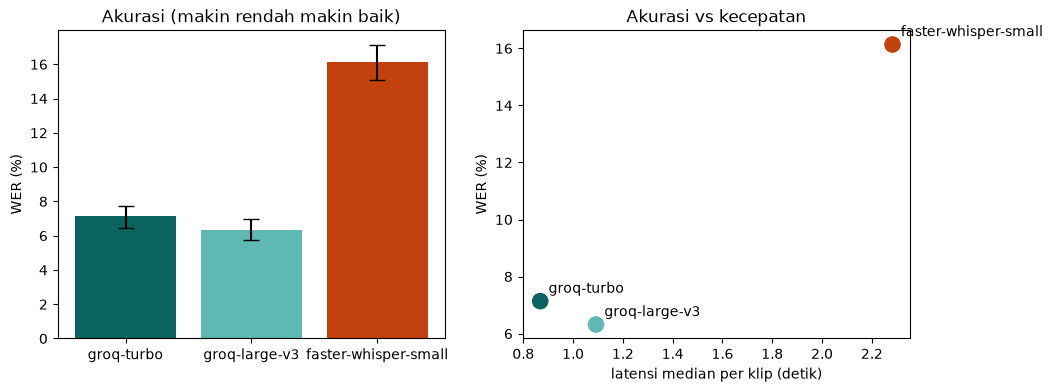

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#0B635F", "#5FB8B2", "#C2410C"][: len(results)]
left.bar(results.index, results.WER * 100, color=colors,
         yerr=[(results.WER - results["WER bawah"]) * 100, (results["WER atas"] - results.WER) * 100], capsize=6)
left.set_ylabel("WER (%)")
left.set_title("Akurasi (makin rendah makin baik)")
right.scatter(results["latensi median"], results.WER * 100, s=120, color=colors)
for name, row in results.iterrows():
    right.annotate(name, (row["latensi median"], row.WER * 100), xytext=(6, 6), textcoords="offset points")
right.set_xlabel("latensi median per klip (detik)")
right.set_ylabel("WER (%)")
right.set_title("Akurasi vs kecepatan")
kit.save_figure(fig, "asr_fleurs_perbandingan.png")
plt.show()

In [10]:
def worst(model, n=5):
    part = runs[runs.model == model].copy()
    part["WER klip"] = [e / max(n_ref, 1) for e, n_ref in (wer.word_errors(r, h) for r, h in zip(part.raw_transcription, part.text))]
    return part.nlargest(n, "WER klip")[["file", "WER klip", "raw_transcription", "text"]]


for name in results.index:
    print(name)
    display(worst(name))

groq-turbo


,file,WER klip,raw_transcription,text
268,clip_00268.wav,0.666667,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lak Ha Sing juga menampilkan capan Bok Bayan, penyanyi racu Kandel..."
192,clip_00192.wav,0.571429,Internet mengombinasikan elemen komunikasi massa dan antarpribadi.,Internet mengundunasikan elemen komunikasi masyarakat dan antar pr...
327,clip_00327.wav,0.500000,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lakha Singh juga menampilkan capan bok bajan, menyanyi Raju Kandel..."
515,clip_00515.wav,0.461538,Ini lebih tipis di bawah maria dan lebih tebal di bawah dataran ti...,ini lebih tipis dibawah mahraya dan lebih depan dibawah dataran ti...
137,clip_00137.wav,0.444444,"Di iklim hangat Timur Tengah, rumah tidak begitu penting.",Hai diikim hangat di murtengah rumah tidak begitu penting


groq-large-v3


,file,WER klip,raw_transcription,text
1140,clip_00453.wav,0.583333,"Bus Scotturb 403 rutin berangkat ke Sintra, berhenti di Cabo da Roca.",Bus Code Code 403 roti penangkat ke Sintra berhenti di Kapo Daroka.
879,clip_00192.wav,0.571429,Internet mengombinasikan elemen komunikasi massa dan antarpribadi.,Internet mengimbinasikan elemen komunikasi masyarakat dan antar-an...
955,clip_00268.wav,0.500000,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lakha Singh juga menampilkan capan bok bayan, penyanyi racu Kandel..."
1014,clip_00327.wav,0.500000,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lakha Singh juga menampilkan capan bok bhajan, menyanyi rajukan di..."
1225,clip_00538.wav,0.466667,"Layaknya pasang surut yang terjadi akibat bulan menarik bumi, Bima...",Layaknya pasang surut yang terjadi agar bulan menaip bumi di masa ...


faster-whisper-small


,file,WER klip,raw_transcription,text
1742,clip_00368.wav,0.933333,Anak-anak liar mungkin pernah mengalami pelecehan atau trauma bera...,Anak-anak tidak mungkin permakna malam biasa anak-anak tau-tau mem...
1737,clip_00363.wav,0.882353,Kapal pesiar Saint Petersburg termasuk waktu di kota. Penumpang ka...,Kapal persyaratan bisa dan pencet persyaratannya.
1827,clip_00453.wav,0.750000,"Bus Scotturb 403 rutin berangkat ke Sintra, berhenti di Cabo da Roca.","Bus Code God 403 Rotin Perangkat Kesintra, berhenti di Kapo Danoka"
1683,clip_00309.wav,0.733333,Mosasaurus merupakan predator puncak di masanya sehingga ia tidak ...,Musa Saurus merupakan beredator puncak demasahnya sehingga ia tak ...
1496,clip_00122.wav,0.727273,Kru pemadam kebakaran akhirnya berhasil memadamkan api pada pukul ...,Krup Madam Bapakaran akhirnya berhasil Madam M.A.P. Adaptegol 23.35


## 6. Kesimpulan

FLEURS berisi ucapan yang dibacakan dengan jelas. Jawaban Cek Paham spontan dan penuh istilah teknis, jadi WER sebenarnya kemungkinan lebih tinggi dari angka di sini.

In [11]:
best = results.WER.idxmin()
fastest = results["latensi median"].idxmin()
results.round(4).to_csv(OUT / "ringkasan_model.csv")
runs.drop(columns=["durasi"]).to_csv(OUT / "per_klip.csv", index=False)

kit.write_summary(OUT / "ringkasan.md", f"ASR Cek Paham pada FLEURS id_id ({SPLIT}, {len(sample)} klip)", {
    "Hasil": kit.md_table(comparison.round(3)),
    "Dilewati": "\n".join(f"- {k}: {v}" for k, v in skipped.items()) or "- tidak ada",
    "Temuan": f"- WER terendah: {best} ({results.WER[best]:.1%}).\n"
              f"- Tercepat: {fastest} (median {results['latensi median'][fastest]:.2f} detik per klip).\n"
              "- Model produksi saat ini adalah groq-turbo.",
    "Batasan": "Ucapan dibacakan dan bersih, jadi WER jawaban spontan kemungkinan lebih tinggi. "
               "Waktu tunggu 60-90 detik adalah perkiraan.",
})
print((OUT / "ringkasan.md").read_text())

# ASR Cek Paham pada FLEURS id_id (test, 687 klip)

## Hasil

| model | WER | CER | latensi median | RTF median | tunggu 60 dtk audio | tunggu 90 dtk audio |
|---|---|---|---|---|---|---|
| groq-turbo | 0.071 | 0.023 | 0.868 | 0.069 | 3.07 | 4.456 |
| groq-large-v3 | 0.063 | 0.02 | 1.092 | 0.089 | 4.981 | 7.289 |
| faster-whisper-small | 0.161 | 0.046 | 2.283 | 0.195 | 6.999 | 9.9 |

## Dilewati

- tidak ada

## Temuan

- WER terendah: groq-large-v3 (6.3%).
- Tercepat: groq-turbo (median 0.87 detik per klip).
- Model produksi saat ini adalah groq-turbo.

## Batasan

Ucapan dibacakan dan bersih, jadi WER jawaban spontan kemungkinan lebih tinggi. Waktu tunggu 60-90 detik adalah perkiraan.

